In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [43]:
run_name = "tinystories-lr-3e-4"

In [44]:
df = pd.read_json(f"../runs/{run_name}/metrics.jsonl", lines=True)
df

,step,time,train_loss,lr,val_loss
0,10,9.62,9.130500,0.000025,NaN
1,20,16.53,8.733696,0.000050,NaN
2,30,23.33,8.108845,0.000075,NaN
3,40,30.15,7.457410,0.000100,NaN
4,50,36.97,6.779232,0.000125,NaN
...,...,...,...,...,...
66,4700,3347.95,1.879144,0.000033,NaN
67,4800,3415.03,1.849635,0.000031,NaN
68,4900,3482.38,1.794821,0.000030,NaN
69,5000,3549.64,1.824527,0.000030,NaN


In [45]:
train = df[df["train_loss"].notna()]
train

,step,time,train_loss,lr,val_loss
0,10,9.62,9.130500,0.000025,NaN
1,20,16.53,8.733696,0.000050,NaN
2,30,23.33,8.108845,0.000075,NaN
3,40,30.15,7.457410,0.000100,NaN
4,50,36.97,6.779232,0.000125,NaN
...,...,...,...,...,...
65,4600,3280.82,1.826623,0.000034,NaN
66,4700,3347.95,1.879144,0.000033,NaN
67,4800,3415.03,1.849635,0.000031,NaN
68,4900,3482.38,1.794821,0.000030,NaN


In [46]:
val = df[df["val_loss"].notna()]
val

,step,time,train_loss,lr,val_loss
16,500,362.32,NaN,NaN,2.667711
22,1000,722.37,NaN,NaN,2.318669
28,1500,1080.53,NaN,NaN,2.138219
34,2000,1439.36,NaN,NaN,2.022097
40,2500,1796.85,NaN,NaN,1.948088
46,3000,2151.84,NaN,NaN,1.892487
52,3500,2509.45,NaN,NaN,1.852611
58,4000,2861.55,NaN,NaN,1.823649
64,4500,3213.12,NaN,NaN,1.805595
70,5000,3704.76,NaN,NaN,1.800742


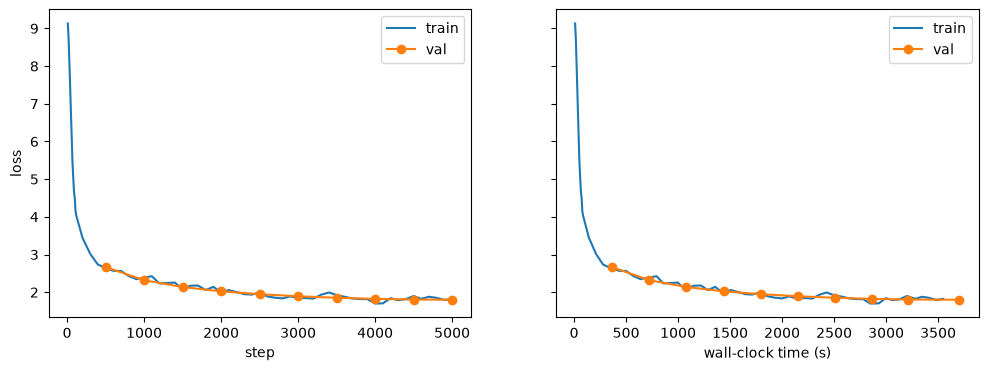

In [47]:
fig, (ax_step, ax_time) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, x in [(ax_step, "step"), (ax_time, "time")]:
    ax.plot(train[x], train["train_loss"], label="train")
    ax.plot(val[x], val["val_loss"], label="val", marker="o")
    ax.set_xlabel("step" if x == "step" else "wall-clock time (s)")
    ax.legend()

ax_step.set_ylabel("loss")
fig.savefig(f"../runs/{run_name}/loss.png", dpi=150, bbox_inches="tight")
plt.show()

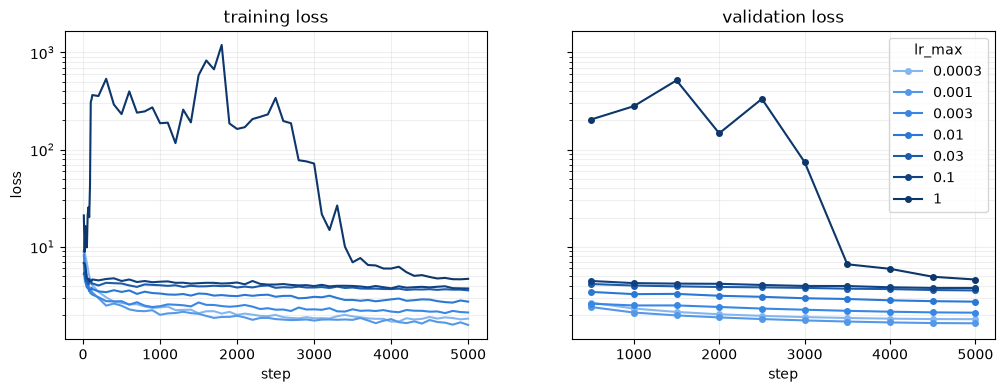

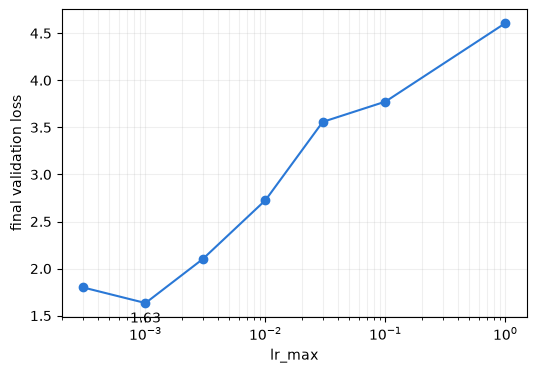

In [48]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

runs_dir = "../runs"
run_names = ["tinystories-base-32b"] + [os.path.basename(p) for p in glob.glob(f"{runs_dir}/tinystories-lr-*")]

runs = []
for run_name in run_names:
    with open(f"{runs_dir}/{run_name}/config.json") as f:
        lr = json.load(f)["optimizer_lr_max"]
    df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
    runs.append((lr, df))
runs.sort(key=lambda run: run[0])

# One blue ramp: light = low learning rate, dark = high learning rate
ramp = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
colors = [ramp[i] for i in np.linspace(0, len(ramp) - 1, len(runs)).round().astype(int)]

fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for (lr, df), color in zip(runs, colors):
    train = df[df["train_loss"].notna()]
    val = df[df["val_loss"].notna()]
    ax_train.plot(train["step"], train["train_loss"], color=color, linewidth=1.5, label=f"{lr:g}")
    ax_val.plot(val["step"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=4, label=f"{lr:g}")

for ax, title in [(ax_train, "training loss"), (ax_val, "validation loss")]:
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.2)
    # ax.set_ylim(1.4, 10)  # uncomment to zoom in on the runs that converged

ax_train.set_ylabel("loss")
ax_val.legend(title="lr_max")
fig.savefig(f"{runs_dir}/lr_sweep_curves.png", dpi=150, bbox_inches="tight")
plt.show()

final = [(lr, df["val_loss"].dropna().iloc[-1]) for lr, df in runs]
lrs, final_losses = zip(*final)
best_lr, best_loss = min(final, key=lambda run: run[1])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(lrs, final_losses, color="#2a78d6", linewidth=1.5, marker="o", markersize=6)
ax.annotate(f"{best_loss:.2f}", (best_lr, best_loss), textcoords="offset points", xytext=(0, -14), ha="center")
ax.set_xscale("log")
ax.set_xlabel("lr_max")
ax.set_ylabel("final validation loss")
ax.grid(True, which="both", alpha=0.2)
fig.savefig(f"{runs_dir}/lr_sweep_final.png", dpi=150, bbox_inches="tight")
plt.show()